# Load dataset

In [176]:
import numpy as np
import pandas as pd

In [177]:
pd.set_option("display.max_columns", None)

file_id = "1jVzIRp6zxrGVDXRtuG-8mc6CzHrbQFED"
url = f"https://drive.google.com/uc?export=download&id={file_id}"

df = pd.read_csv(
    url,
    parse_dates=["started_at"],
    dtype={"y_overdue": "boolean", "prev_late": "boolean"},
)

df.head()

,id,started_at,customer_id,client_id,tenant,hour,dow,month,is_weekend,plan_hours,n_batteries,model,deposit_kind,deposit_amount,price_total,prepaid_share,client_residency,block_missing,issued_by_employee_id,first_visit,client_prev_rentals,client_prev_late_rate,client_prev_lost,prev_late,days_since_prev,y_overdue,y_lost
0,65f0da3c-7abb-4f9c-b2b7-1968b8a663e2,2025-01-18 12:19:51+00:00,2975e970-5ed2-46f0-b809-f455e9873912,01d32244-c1b4-4a1a-97c1-b414ab17aa69,synth-a,15,5,1,True,72.000000,1,Trail 350,document,NaN,5720.0,0.0,local,False,23b8c1e9-3924-46de-beb1-3b9046685257,True,0,NaN,0,<NA>,NaN,False,False
1,9dddd117-7806-49e8-9857-f0891492517a,2025-01-18 13:01:54+00:00,e5ceac23-aff7-488d-aada-d07f2d6b89e7,662e7ea7-9c74-4faf-8fed-aa3b52e3b310,synth-a,16,5,1,True,2.000000,2,Cargo 500,cash,2000.0,870.0,0.0,local,False,17fc695a-07a0-4a6e-8822-e8f36c031199,False,2,NaN,0,<NA>,7.291227,False,False
2,5f2c2c26-7b12-4db4-a509-1af3c7a9b788,2025-01-18 14:32:11+00:00,3bd8a8e5-feaf-47c1-9ff9-6ac8294b1d6f,53028b18-d032-4689-8dd3-b231402c1e98,synth-a,17,5,1,True,2.000000,1,Cargo 500,document,NaN,NaN,NaN,local,False,8fadc1a6-06cb-4fb3-9a1d-e644815ef6d1,False,1,NaN,0,<NA>,19.314884,False,False
3,e9a9ea82-7552-46e3-abd2-277e49bae976,2025-01-18 14:58:59+00:00,ef4e31fe-b93b-4061-95bd-125ecfdc8f7b,918eade9-dbd4-44b9-89d6-158602d45aad,synth-c,16,5,1,True,4.016944,2,Cargo 500,NaN,NaN,NaN,NaN,NaN,True,6e996e3e-e3b1-47fc-8a34-50fc9918ee46,True,0,NaN,0,<NA>,NaN,False,False
4,2a036585-d898-484e-834d-216eb0b615c0,2025-01-18 15:12:19+00:00,d3497354-5320-4fc3-9f36-8a17065f8f69,7626e160-db24-44cb-85aa-e5ca667d6f8e,synth-b,20,5,1,True,0.794722,1,Urban 250,NaN,NaN,NaN,NaN,NaN,True,50f0fd0a-750c-4b75-8ccc-9bc2a53f8a28,True,0,NaN,0,<NA>,NaN,True,False


# EDA

## Base

In [178]:
df.shape, df.duplicated().sum()

((39344, 27), np.int64(0))

In [179]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 39344 entries, 0 to 39343
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype              
---  ------                 --------------  -----              
 0   id                     39344 non-null  str                
 1   started_at             39344 non-null  datetime64[us, UTC]
 2   customer_id            39344 non-null  str                
 3   client_id              39344 non-null  str                
 4   tenant                 39344 non-null  str                
 5   hour                   39344 non-null  int64              
 6   dow                    39344 non-null  int64              
 7   month                  39344 non-null  int64              
 8   is_weekend             39344 non-null  bool               
 9   plan_hours             39344 non-null  float64            
 10  n_batteries            39344 non-null  int64              
 11  model                  39344 non-null  str                
 12  d

In [180]:
KEYS = ["id", "started_at", "customer_id", "client_id"]
TARGET = "y_overdue"
NUM = ["hour", "month", "plan_hours", "n_batteries", "deposit_amount", "price_total",
       "prepaid_share", "client_prev_rentals", "client_prev_late_rate", "client_prev_lost",
       "days_since_prev"]
CAT = ["tenant", "dow", "model", "deposit_kind", "client_residency", "issued_by_employee_id"]
BOOL = ["is_weekend", "block_missing", "first_visit", "prev_late"]

### Nulls

In [181]:
nulls = df.isnull().sum().sort_values(ascending=False)
nulls[nulls > 0]

deposit_amount           32508
prepaid_share            19986
client_residency         17856
price_total              17854
deposit_kind             17787
client_prev_late_rate    15960
prev_late                15960
days_since_prev          15633
y_overdue                  391
dtype: int64

In [182]:
df = df.drop(columns="y_lost").dropna(subset=["y_overdue"]).reset_index(drop=True)
df["y_overdue"] = df["y_overdue"].astype("int8")
df[BOOL] = df[BOOL].astype("float32")

In [183]:
print(df.shape, df["y_overdue"].isna().sum(), df["y_overdue"].dtype)

(38953, 26) 0 int8


## Describe Data

### NUM

In [184]:
desc = df[NUM].describe(percentiles=[.01, .25, .5, .75, .99]).T
desc["missing_%"] = (df[NUM].isna().mean() * 100).round(1)
desc["skew"] = df[NUM].skew().round(2)
desc["kurt"] = df[NUM].kurt().round(2)

q1, q3 = df[NUM].quantile(.25), df[NUM].quantile(.75)
iqr = q3 - q1
outliers = ((df[NUM] < q1 - 1.5 * iqr) | (df[NUM] > q3 + 1.5 * iqr)).mean() * 100
desc["outliers_%"] = outliers.round(1)

desc

,count,mean,std,min,1%,25%,50%,75%,99%,max,missing_%,skew,kurt,outliers_%
hour,38953.0,12.290504,3.331980,9.000000,9.000000,9.000000,12.000000,15.000000,20.000000,20.000000,0.0,0.68,-0.69,0.0
month,38953.0,6.571715,2.813073,1.000000,1.000000,5.000000,7.000000,9.000000,12.000000,12.000000,0.0,-0.12,-0.67,0.0
plan_hours,38953.0,21.441388,38.225681,0.002778,0.542644,2.000000,4.000000,24.000000,168.000000,168.000000,0.0,2.85,7.92,9.5
n_batteries,38953.0,1.303212,0.459652,1.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,0.0,0.86,-1.27,0.0
deposit_amount,6806.0,2726.417867,1461.561879,1000.000000,1000.000000,2000.000000,2000.000000,3000.000000,5000.000000,5000.000000,82.5,0.47,-1.09,4.2
price_total,21277.0,2237.156084,2766.368969,270.000000,290.000000,890.000000,1440.000000,2210.000000,15362.400000,17320.000000,45.4,3.28,11.40,6.2
prepaid_share,19160.0,0.550861,0.445218,0.000000,0.000000,0.000000,0.500000,1.000000,1.000000,1.000000,50.8,-0.20,-1.71,0.0
client_prev_rentals,38953.0,2.115344,2.875652,0.000000,0.000000,0.000000,1.000000,3.000000,13.000000,26.000000,0.0,2.10,5.83,6.0
client_prev_late_rate,23225.0,0.082735,0.208251,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,40.4,3.14,9.95,12.6
client_prev_lost,38953.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,NaN,NaN,0.0


### CAT

In [185]:
summary = pd.DataFrame({
    "nunique": df[CAT].nunique(),
    "missing": df[CAT].isna().sum(),
    "top": df[CAT].mode().iloc[0],
    "top_share_%": df[CAT].apply(lambda s: s.value_counts(normalize=True).iloc[0] * 100).round(1),
    "values": [df[c].dropna().unique().tolist() for c in CAT],
}).sort_values("nunique")
summary

,nunique,missing,top,top_share_%,values
client_residency,2,17681,local,80.4,"[local, tourist]"
tenant,3,0,synth-b,50.1,"[synth-a, synth-c, synth-b]"
deposit_kind,3,17612,none,36.7,"[document, cash, none]"
model,3,0,Cargo 500,36.1,"[Trail 350, Cargo 500, Urban 250]"
dow,7,0,5,16.2,"[5, 6, 0, 1, 2, 3, 4]"
issued_by_employee_id,12,0,344a54b8-42c1-4a62-af48-e8d550fd9d3f,12.7,"[23b8c1e9-3924-46de-beb1-3b9046685257, 17fc695..."


### BOOL

In [186]:
bool_summary = df[BOOL].describe().T.join(
    pd.DataFrame({
        "missing_%": (df[BOOL].isna().mean() * 100).round(1),
        "share_1_%": (df[BOOL].mean() * 100).round(1),
    })
)
bool_summary

,count,mean,std,min,25%,50%,75%,max,missing_%,share_1_%
is_weekend,38953.0,0.322774,0.467543,0.0,0.0,0.0,1.0,1.0,0.0,32.299999
block_missing,38953.0,0.391703,0.488137,0.0,0.0,0.0,1.0,1.0,0.0,39.200001
first_visit,38953.0,0.395400,0.488943,0.0,0.0,0.0,1.0,1.0,0.0,39.500000
prev_late,23225.0,0.075694,0.264514,0.0,0.0,0.0,0.0,1.0,40.4,7.600000


## Temp split and Preparation

Order of the notebook:
- **Before the split** (sections 1-3): loading, deterministic cleaning (drop `y_lost` and rows without `y_overdue`, dtype casting) and descriptive EDA that does not use the target.
- **Split:** time-based, the first 80% of checkouts by `started_at` go to `df_train`, the last 20% to `df_test`. No shuffling: the overdue rate drifts over time and the client-history features are built from the past.
- **After the split** (Visualize, Correlation with target, Corr Matrix below): everything that uses the target or influences decisions works on `df_train` only. `df_test` is used only by the check after the split and, later, for `transform` / `predict`.

In [187]:
from sklearn.model_selection import train_test_split

# time-based split without shuffling, so stratify / random_state do not apply
assert df["started_at"].is_monotonic_increasing
df_train, df_test = train_test_split(df, test_size=0.2, shuffle=False)

In [188]:
print(df_train.shape, df_test.shape)
assert df_train.index.intersection(df_test.index).empty
assert df_train["started_at"].max() <= df_test["started_at"].min()
print(df_train[TARGET].value_counts(normalize=True).round(4).to_dict(),
      df_test[TARGET].value_counts(normalize=True).round(4).to_dict())

(31162, 26) (7791, 26)
{0: 0.9154, 1: 0.0846} {0: 0.9239, 1: 0.0761}


## Visualize

In [189]:
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

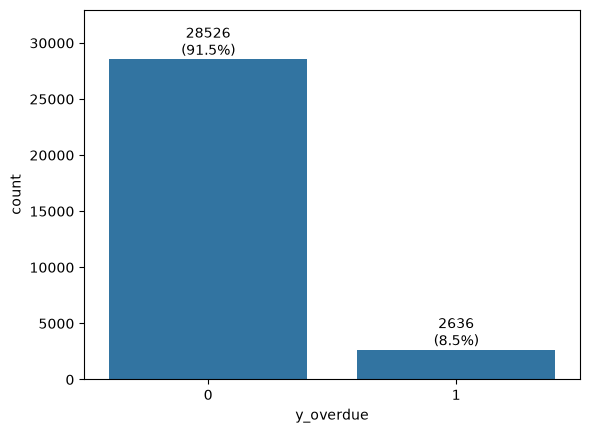

In [190]:
# after split: df_train only
ax = sns.countplot(data=df_train, x=TARGET)
for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{int(h)}\n({h / len(df_train):.1%})",
                (p.get_x() + p.get_width() / 2, h),
                ha="center", va="bottom")
ax.set_ylim(0, ax.get_ylim()[1] * 1.1)
plt.show()

### Conclusion
Class imbalance.
The main metric is PR AUC (average precision).
Stratification is required.

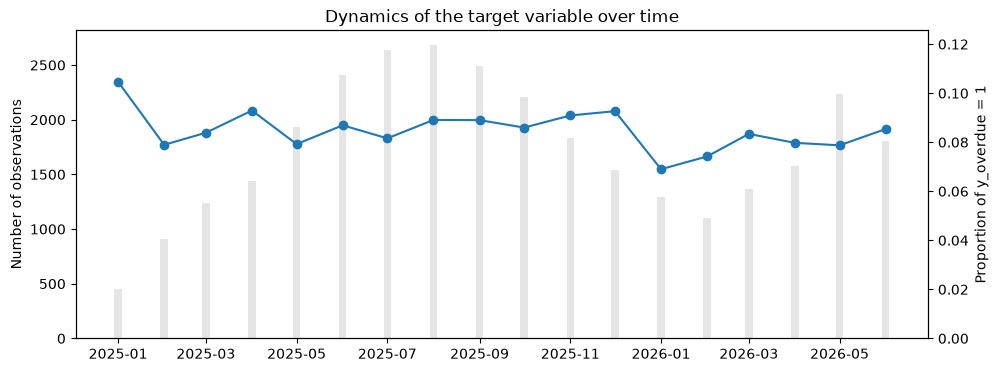

In [191]:
# after split: df_train only
ts = (
    df_train.set_index("started_at")["y_overdue"]
      .resample("MS")
      .agg(rate="mean", n="size")
)

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(ts.index, ts["n"], width=5, alpha=0.2, color="gray")
ax1.set_ylabel("Number of observations")

ax2 = ax1.twinx()
ax2.plot(ts.index, ts["rate"], marker="o", color="C0")
ax2.set_ylabel("Proportion of y_overdue = 1")
ax2.set_ylim(0, ts["rate"].max() * 1.2)

plt.title("Dynamics of the target variable over time")
plt.show()

## Correlation with target

In [192]:
# after split: df_train only
from sklearn.metrics import roc_auc_score

base = df_train[TARGET].mean()   # The total percentage of delays, the starting point for all comparisons
base.round(3)

np.float64(0.085)

In [193]:
# after split: df_train only
# Automatic sorting of features by type
const = [c for c in NUM + BOOL if df_train[c].nunique() <= 1]               # constants (client_prev_lost)
DISC  = [c for c in NUM if c not in const and df_train[c].nunique() <= 12]  # discrete: hour, month, n_batteries ...
CONT  = [c for c in NUM if c not in const and c not in DISC]          # continuous
LOW   = [c for c in CAT if df_train[c].nunique() <= 20]                     # categorical with few values
HIGH  = [c for c in CAT if c not in LOW]                              # with many values (issued_by_employee_id)
print("const:", const, "\nDISC:", DISC, "\nCONT:", CONT, "\nLOW:", LOW, "\nHIGH:", HIGH)

const: ['client_prev_lost'] 
DISC: ['hour', 'month', 'n_batteries', 'deposit_amount', 'prepaid_share'] 
CONT: ['plan_hours', 'price_total', 'client_prev_rentals', 'client_prev_late_rate', 'days_since_prev'] 
LOW: ['tenant', 'dow', 'model', 'deposit_kind', 'client_residency', 'issued_by_employee_id'] 
HIGH: []


### NUM + BOOL (AUC of one feature)

In [194]:
# after split: df_train only
rows = []
for c in CONT + DISC + BOOL:
    s = df_train[[c, TARGET]].dropna()
    rows.append({"feature": c, "n": len(s), "auc": roc_auc_score(s[TARGET], s[c])})

rank = (pd.DataFrame(rows)
          .assign(corr=lambda t: (t["auc"] - 0.55)) # 0.55–0.65: weak signal
          .sort_values("corr", ascending=False)
          .round(3))
rank

,feature,n,auc,corr
0,plan_hours,31162,0.682,0.132
1,price_total,16965,0.676,0.126
12,first_visit,31162,0.555,0.005
3,client_prev_late_rate,18550,0.553,0.003
5,hour,31162,0.539,-0.011
10,is_weekend,31162,0.534,-0.016
13,prev_late,18550,0.518,-0.032
6,month,31162,0.513,-0.037
11,block_missing,31162,0.502,-0.048
8,deposit_amount,5416,0.502,-0.048


### Groups

In [195]:
# after split: df_train only
def rate_table(c, min_n=100):
    g = df_train.groupby(c, dropna=False)[TARGET].agg(rate="mean", n="size")
    g = g[g["n"] >= min_n]                                   # rare groups are noisy
    g["lift"] = (g["rate"] / base).round(2)
    g["z"] = ((g["rate"] - base) / (g["rate"].clip(1e-9, 1 - 1e-9) * (1 - g["rate"].clip(1e-9, 1 - 1e-9)) / g["n"]) ** 0.5).round(1)
    g["rate_%"] = (g["rate"] * 100).round(1)
    return g[["rate_%", "n", "lift", "z"]]

for c in LOW + DISC + BOOL:
    print(f"\n=== {c} === (base {base:.1%})")
    print(rate_table(c).sort_values("rate_%").to_string())


=== tenant === (base 8.5%)
         rate_%      n  lift    z
tenant                           
synth-c     7.2   6105  0.85 -3.8
synth-a     8.2   9518  0.97 -1.1
synth-b     9.1  15539  1.08  2.9

=== dow === (base 8.5%)
     rate_%     n  lift    z
dow                         
3       7.1  4225  0.84 -3.4
0       7.4  4192  0.88 -2.6
2       7.4  4110  0.87 -2.7
1       8.1  4327  0.96 -0.8
4       8.4  4194  0.99 -0.2
5       9.9  5089  1.17  3.5
6      10.2  5025  1.21  4.1

=== model === (base 8.5%)
           rate_%      n  lift    z
model                              
Cargo 500     8.1  11451  0.96 -1.4
Trail 350     8.5  10048  1.01  0.2
Urban 250     8.8   9663  1.04  1.2

=== deposit_kind === (base 8.5%)
              rate_%      n  lift     z
deposit_kind                           
document         4.8   4807  0.57 -11.9
cash             7.0   5963  0.82  -4.6
NaN              8.4  14140  1.00  -0.1
none            12.8   6252  1.51  10.2

=== client_residency === (base 8.5

### Dependency for continuous features

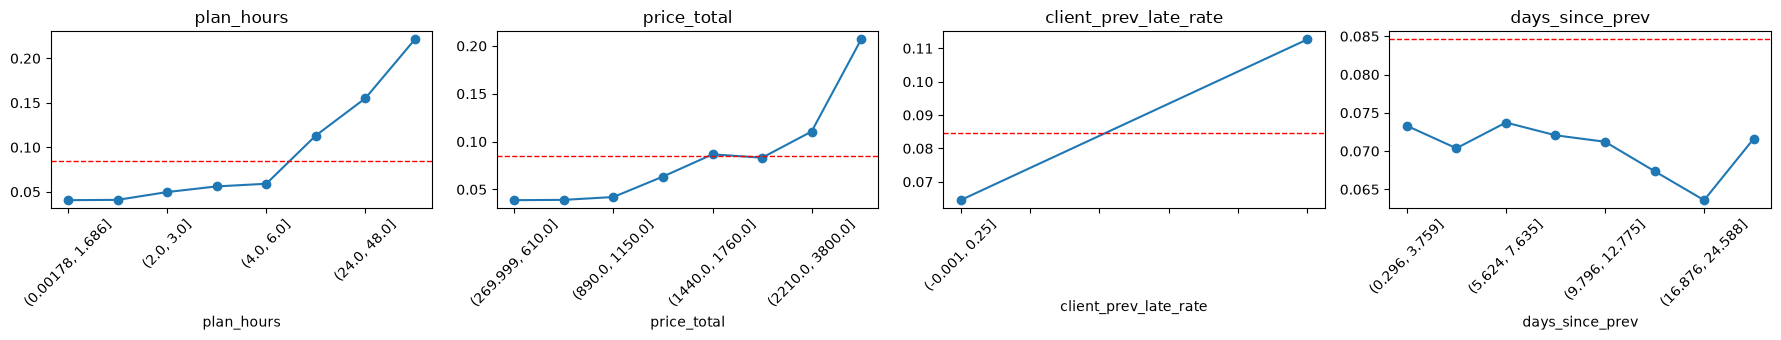

In [196]:
# after split: df_train only
top = rank[rank["feature"].isin(CONT)]["feature"].head(4).tolist()
fig, axes = plt.subplots(1, len(top), figsize=(4.5 * len(top), 3.5))
for ax, c in zip(np.atleast_1d(axes), top):
    bins = pd.qcut(df_train[c], q=8, duplicates="drop")
    df_train.groupby(bins, observed=True)[TARGET].mean().plot(marker="o", ax=ax)
    ax.axhline(base, color="red", ls="--", lw=1)
    ax.set_title(c)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

### NAs

In [197]:
# after split: df_train only
na_cols = [c for c in df_train.columns if df_train[c].isna().any() and c != TARGET]
na_effect = pd.DataFrame({
    c: {"rate_if_NA_%": df_train.loc[df_train[c].isna(), TARGET].mean() * 100,
        "rate_if_present_%": df_train.loc[df_train[c].notna(), TARGET].mean() * 100,
        "n_NA": df_train[c].isna().sum()}
    for c in na_cols
}).T.round(1)
na_effect

,rate_if_NA_%,rate_if_present_%,n_NA
deposit_kind,8.4,8.5,14140.0
deposit_amount,8.8,6.9,25746.0
price_total,8.6,8.4,14197.0
prepaid_share,8.4,8.5,15880.0
client_residency,8.6,8.3,14201.0
client_prev_late_rate,10.6,7.0,12612.0
prev_late,10.6,7.0,12612.0
days_since_prev,10.6,7.0,12286.0


## Corr Matrix

### NUM + BOOL

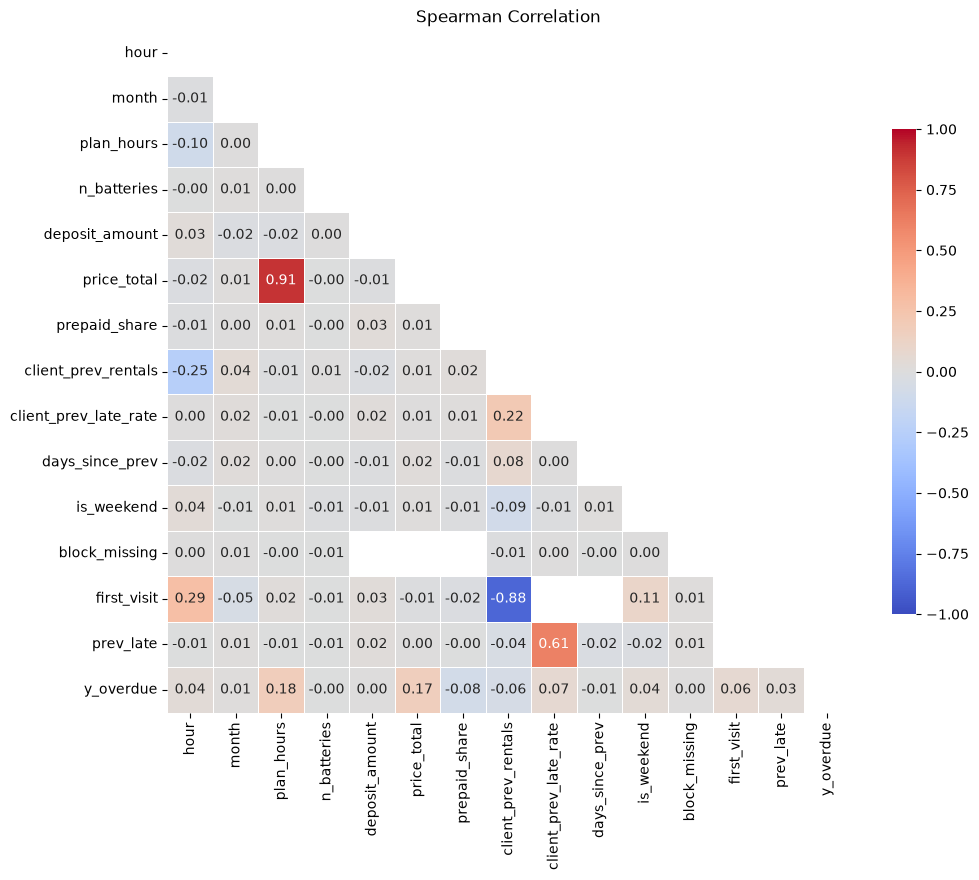

In [198]:
# after split: df_train only
corr_cols = [c for c in NUM + BOOL if df_train[c].nunique() > 1]   # client_prev_lost constant is eliminated
corr = df_train[corr_cols + [TARGET]].astype("float64").corr(method="spearman")

mask = np.triu(np.ones_like(corr, dtype=bool))               # show only the lower triangle
plt.figure(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, square=True, linewidths=.5,
            cbar_kws={"shrink": .7})
plt.title("Spearman Correlation")
plt.show()

In [199]:
pairs = corr.where(~mask).stack().rename_axis(["f1", "f2"]).reset_index(name="corr")
pairs = pairs.loc[pairs["corr"].abs() > 0.5].sort_values("corr", key=abs, ascending=False)
pairs.round(2)

,f1,f2,corr
77,price_total,plan_hours,0.91
187,first_visit,client_prev_rentals,-0.88
203,prev_late,client_prev_late_rate,0.61


In [200]:
# after split: df_train only
# first visit = no prev rents?
print((df_train["first_visit"].astype(bool) == (df_train["client_prev_rentals"] == 0)).mean())

1.0


In [201]:
# after split: df_train only
d = df_train.dropna(subset=["price_total"]).copy()
d["price_ratio"] = d["price_total"] / d.groupby(d["plan_hours"].round(0))["price_total"].transform("median")
print(d.groupby(TARGET)["price_ratio"].describe().round(2))

# what explains the variation within the tariff
x = d[d["plan_hours"].round(0) == 24]
print(x.groupby("n_batteries")["price_total"].median())
print(x.groupby("model")["price_total"].median())

             count  mean   std   min   25%  50%   75%   max
y_overdue                                                  
0          15545.0  1.09  0.44  0.30  0.88  1.0  1.22  7.82
1           1420.0  1.06  0.33  0.68  0.88  1.0  1.22  5.95
n_batteries
1    1770.0
2    1805.0
Name: price_total, dtype: float64
model
Cargo 500    2250.0
Trail 350    1750.0
Urban 250    1490.0
Name: price_total, dtype: float64


There is no leak

### CAT

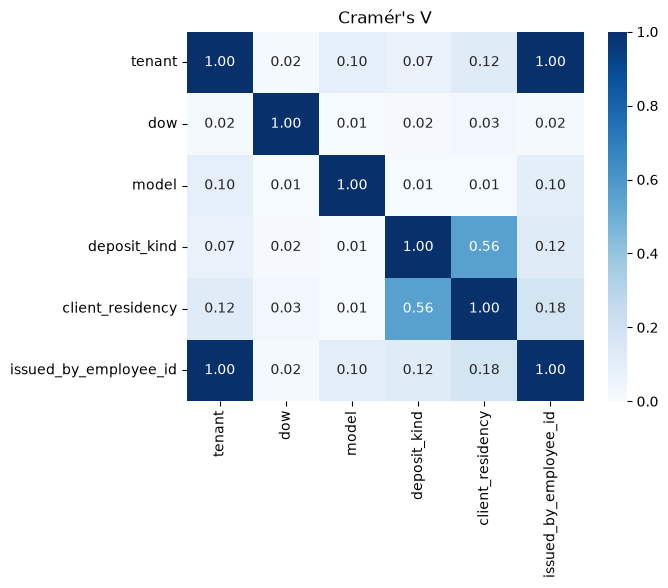

In [202]:
# after split: df_train only
from scipy.stats import chi2_contingency

def cramers_v(a, b):
    t = pd.crosstab(a, b)
    chi2 = chi2_contingency(t, correction=False)[0]
    n = t.values.sum()
    return (chi2 / (n * (min(t.shape) - 1))) ** 0.5

cat_cols = [c for c in CAT if df_train[c].nunique() <= 20]          # without issued_by_employee_id
cv = pd.DataFrame(
    [[cramers_v(df_train[a].fillna("NA"), df_train[b].fillna("NA")) for b in cat_cols] for a in cat_cols],
    index=cat_cols, columns=cat_cols)

sns.heatmap(cv, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Cramér's V")
plt.show()

In [203]:
# after split: df_train only
print(pd.crosstab(df_train["deposit_kind"].isna(), df_train["client_residency"].isna()))
print(pd.crosstab(df_train["block_missing"], df_train["deposit_kind"].isna()))

# association only where both features are filled in
m = df_train.dropna(subset=["deposit_kind", "client_residency"])
print(cramers_v(m["deposit_kind"], m["client_residency"]))

client_residency  False  True 
deposit_kind                  
False             15269   1753
True               1692  12448
deposit_kind   False  True 
block_missing              
0.0            17022   1887
1.0                0  12253
0.15734415616170908


### Conclusion
1. It is required to leave one attribute `first_visit` or `client_prev_rentals`
2. Remove `issued_by_employee_id` and leave only `tenant` because V = 1

## EDA General Conclusion
1. Class imbalance.
2. The main metric is PR AUC (average precision).
3. Stratification is required.
4. Remove `first_visit` and leave only `client_prev_rentals` because first_visit is completely derived from client_prev_rentals
5. Remove `issued_by_employee_id` and leave only `tenant` because V = 1

# Final Cleaning and Split

In [204]:
# Remove dropped features
CAT = ["tenant", "dow", "model", "deposit_kind", "client_residency"]
BOOL = ["is_weekend", "block_missing", "prev_late"]

In [205]:
# deterministic cleaning from the conclusions above
df = df.drop(columns=[
    "first_visit",              # first_visit is completely derived from client_prev_rentals
    "issued_by_employee_id",    # nested in tenant (V = 1)
])
df.shape

(38953, 24)

In [206]:
# time-based split without shuffling: train 60% / val 20% / test 20%
# (stratify does not work with shuffle=False; the overdue rate drifts over time)
assert df["started_at"].is_monotonic_increasing
df_full_train, df_test = train_test_split(df, test_size=0.2, shuffle=False)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, shuffle=False)
len(df_train), len(df_val), len(df_test)

(23371, 7791, 7791)

In [207]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [208]:
y_train = df_train[TARGET].values
y_val = df_val[TARGET].values
y_test = df_test[TARGET].values

del df_train[TARGET]
del df_val[TARGET]
del df_test[TARGET]

# Fiting

## Baseline: constant (base rate)

In [209]:
# PR-AUC of a random model equals the share of positives in the evaluated sample
baseline = y_val.mean().round(3)
print("base   ", baseline)

base    0.081


## Base model: logistic regression on `plan_hours`

Time-based split: fit on `df_train`, metrics on `df_val`. `df_test` stays untouched until the final model.

In [210]:
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

lr = make_pipeline(StandardScaler(), LogisticRegression())
lr.fit(df_train[["plan_hours"]], y_train)
p = lr.predict_proba(df_val[["plan_hours"]])[:, 1]

print("base   ", baseline)
print("PR-AUC ", average_precision_score(y_val, p))
print("ROC AUC", roc_auc_score(y_val, p))

base    0.081
PR-AUC  0.15206763948442695
ROC AUC 0.6732587143071859


## Logreg with L2

In [211]:
# without constant client_prev_lost
cols = NUM + BOOL + CAT
df_train = df_train[cols].drop(columns='client_prev_lost')
df_val   = df_val[cols].drop(columns='client_prev_lost')
df_test  = df_test[cols].drop(columns='client_prev_lost')

In [212]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [213]:
num_cols = [c for c in NUM if c in df_train.columns]
bool_cols = [c for c in BOOL if c in df_train.columns]
cat_cols = [c for c in CAT if c in df_train.columns]

prep = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), num_cols),
    ("bool", SimpleImputer(strategy="median", add_indicator=True), bool_cols),
    ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="NA"),
                          OneHotEncoder(handle_unknown="ignore")), cat_cols),
])

In [214]:
X_train = prep.fit_transform(df_train)
X_val = prep.transform(df_val)
X_test = prep.transform(df_test)

In [218]:
rows = []
for C in np.logspace(-4, 2, 13):
    lr = LogisticRegression(C=C, max_iter=1000).fit(X_train, y_train)
    rows.append({
        "C": C,
        "pr_auc_train": average_precision_score(y_train, lr.predict_proba(X_train)[:, 1]),
        "pr_auc_val": average_precision_score(y_val, lr.predict_proba(X_val)[:, 1]),
        "roc_auc_val": roc_auc_score(y_val, lr.predict_proba(X_val)[:, 1]),
    })

res = pd.DataFrame(rows).set_index("C").round(4)
print(res)
best_C = res["pr_auc_val"].idxmax()
print("best C:", best_C)

            pr_auc_train  pr_auc_val  roc_auc_val
C                                                
0.000100          0.1976      0.1762       0.7000
0.000316          0.2035      0.1787       0.7024
0.001000          0.2115      0.1849       0.7043
0.003162          0.2183      0.1909       0.7052
0.010000          0.2219      0.1952       0.7045
0.031623          0.2229      0.1963       0.7036
0.100000          0.2232      0.1967       0.7033
0.316228          0.2233      0.1968       0.7030
1.000000          0.2233      0.1969       0.7030
3.162278          0.2233      0.1971       0.7029
10.000000         0.2233      0.1969       0.7029
31.622777         0.2234      0.1970       0.7029
100.000000        0.2234      0.1970       0.7029
best C: 3.1622776601683795


### Final Logreg L2

In [219]:
from sklearn.base import clone

# склеиваем train и val: индексы уже сброшены, TARGET из датафреймов удалён
df_full_train = pd.concat([df_train, df_val], ignore_index=True)
y_full_train = np.concatenate([y_train, y_val])

# prep переобучается на train + val; clone нужен, чтобы не трогать уже обученный prep
final = make_pipeline(clone(prep), LogisticRegression(C=best_C, max_iter=1000))
final.fit(df_full_train, y_full_train)

# тест смотрим один раз
p_test = final.predict_proba(df_test)[:, 1]
print("base   ", y_test.mean())
print("PR-AUC ", average_precision_score(y_test, p_test))
print("ROC AUC", roc_auc_score(y_test, p_test))

base    0.07611346425362597
PR-AUC  0.1770516151841091
ROC AUC 0.7210144095675818


## HistGradientBoostingClassifier

In [220]:
import itertools
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.preprocessing import OrdinalEncoder

In [221]:
# пропуски и масштаб модель обрабатывает сама; категориям нужны только числовые коды
prep_gb = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan), cat_cols),
    ("rest", "passthrough", num_cols + bool_cols),
])
X_train = prep_gb.fit_transform(df_train)
X_val = prep_gb.transform(df_val)
cat_mask = [True] * len(cat_cols) + [False] * (len(num_cols) + len(bool_cols))

In [222]:
def fit_eval(**params):
    gb = HistGradientBoostingClassifier(
        max_iter=1000, early_stopping=False, categorical_features=cat_mask, random_state=42, **params,
    ).fit(X_train, y_train)
    # PR-AUC на val после каждой итерации -> число деревьев без случайного early stopping
    scores = [average_precision_score(y_val, p[:, 1]) for p in gb.staged_predict_proba(X_val)]
    return int(np.argmax(scores)) + 1, max(scores)

In [235]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import ParameterSampler, TimeSeriesSplit

df_cv = pd.concat([df_train, df_val], ignore_index=True)
y_cv = np.concatenate([y_train, y_val])
X_cv = prep_gb.fit_transform(df_cv)     # порядковые коды не используют таргет, так что утечки нет
folds = list(TimeSeriesSplit(n_splits=4).split(X_cv))
MAX_ITER, STEP = 800, 10                # метрику считаем каждые 10 деревьев, так быстрее

def cv_eval(params):
    curves = []
    for tr, va in folds:
        gb = HistGradientBoostingClassifier(
            max_iter=MAX_ITER, early_stopping=False, categorical_features=cat_mask, random_state=42, **params,
        ).fit(X_cv[tr], y_cv[tr])
        curves.append([average_precision_score(y_cv[va], p[:, 1])
                       for k, p in enumerate(gb.staged_predict_proba(X_cv[va]), 1) if k % STEP == 0])
    curves = np.array(curves)               # фолды x контрольные точки
    mean = curves.mean(axis=0)
    i = int(mean.argmax())                  # одно число деревьев для всех фолдов
    return {"best_iter": (i + 1) * STEP, "pr_auc_cv": mean[i], "std": curves[:, i].std()}


### 1 Iter of tuning

In [236]:
space = {
    "learning_rate":     loguniform(0.02, 0.2),
    "max_leaf_nodes":    randint(2, 32),
    "min_samples_leaf":  loguniform(50, 3000),
    "l2_regularization": loguniform(1e-3, 100),
    "max_features":      uniform(0.3, 0.7),     # доля признаков на разбиение: 0.3 ... 1.0
}

ref = {"learning_rate": 0.05, "max_leaf_nodes": 3, "min_samples_leaf": 800, "l2_regularization": 0.0}
print("reference", {k: round(float(v), 4) for k, v in cv_eval(ref).items()})

rows = []
for p in ParameterSampler(space, n_iter=40, random_state=42):
    params = {**p, "max_leaf_nodes": int(p["max_leaf_nodes"]), "min_samples_leaf": int(p["min_samples_leaf"])}
    rows.append({**params, **cv_eval(params)})

res = pd.DataFrame(rows).sort_values("pr_auc_cv", ascending=False).reset_index(drop=True)
print(res.head(8).round(4).to_string())

reference {'best_iter': 320.0, 'pr_auc_cv': 0.2261, 'std': 0.0178}
   l2_regularization  learning_rate  max_features  max_leaf_nodes  min_samples_leaf  best_iter  pr_auc_cv     std
0             1.4711         0.0687        0.3632               2                92        640     0.2315  0.0227
1             2.8490         0.0487        0.9557               2               795        800     0.2304  0.0203
2             0.0067         0.0207        0.5964               2               112        790     0.2303  0.0223
3             0.0266         0.0218        0.7267               3               269        570     0.2277  0.0195
4             0.0186         0.0353        0.7874               4               171        330     0.2256  0.0185
5             2.1361         0.0780        0.4923               4               345        140     0.2244  0.0180
6             0.0333         0.0250        0.7790              16               820        300     0.2229  0.0152
7             0.1445 

### 2 Iter of tuning

In [239]:
space2 = {
    "learning_rate":     loguniform(0.01, 0.1),
    "min_samples_leaf":  loguniform(50, 1000),
    "l2_regularization": loguniform(1e-3, 100),
    "max_features":      uniform(0.3, 0.7),
}

ref = {"learning_rate": 0.05, "max_leaf_nodes": 3, "min_samples_leaf": 800, "l2_regularization": 0.0}
print("reference", {k: round(float(v), 4) for k, v in cv_eval(ref).items()})

rows = []
for p in ParameterSampler(space2, n_iter=40, random_state=42):
    params = {**p, "max_leaf_nodes": 2, "min_samples_leaf": int(p["min_samples_leaf"])}
    rows.append({**params, **cv_eval(params)})

res = pd.DataFrame(rows).sort_values("pr_auc_cv", ascending=False).reset_index(drop=True)
print(res.head(8).round(4).to_string())

reference {'best_iter': 320.0, 'pr_auc_cv': 0.2261, 'std': 0.0178}
   l2_regularization  learning_rate  max_features  min_samples_leaf  max_leaf_nodes  best_iter  pr_auc_cv     std
0            10.8943         0.0787        0.5226                69               2        560     0.2323  0.0220
1             0.0197         0.0460        0.5182               237               2        790     0.2322  0.0220
2             0.0332         0.0335        0.6024               119               2        800     0.2321  0.0218
3             0.0053         0.0309        0.9900               103               2        800     0.2320  0.0217
4             6.3669         0.0364        0.8397               219               2        800     0.2320  0.0217
5             0.0011         0.0324        0.5922                97               2        800     0.2320  0.0219
6             0.0024         0.0970        0.8406                90               2        330     0.2320  0.0221
7             0.0746 

### Final HistGradientBoostingClassifier

In [240]:
best = res.iloc[0]
params = {"learning_rate": best["learning_rate"], "l2_regularization": best["l2_regularization"],
          "max_features": best["max_features"], "max_leaf_nodes": int(best["max_leaf_nodes"]),
          "min_samples_leaf": int(best["min_samples_leaf"])}

gb_final = HistGradientBoostingClassifier(
    **params, max_iter=int(best["best_iter"]), early_stopping=False,
    categorical_features=cat_mask, random_state=42,
).fit(X_cv, y_cv)

p_test = gb_final.predict_proba(prep_gb.transform(df_test))[:, 1]
print("base   ", y_test.mean())
print("PR-AUC ", average_precision_score(y_test, p_test))
print("ROC AUC", roc_auc_score(y_test, p_test))

base    0.07611346425362597
PR-AUC  0.1924675124704442
ROC AUC 0.737939782785831


## Best Model
